In [26]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

current_file = os.path.abspath('1_eda_and_ml.ipynb')
notebooks = os.path.dirname(current_file)  # на 1 уровень вверх
project = os.path.dirname(notebooks)  # на еще 1 уровень вверх

# Подключаемся к нашей сгенерированной БД
conn = sqlite3.connect(project+'\\data\\bank.db')

#Открываем и читаем SQL-файл
with open(project+'\\src\\extract_data.sql', 'r', encoding='utf-8') as file:
    sql_script = file.read()
    
# Загружаем данные напрямую в DataFrame
df = pd.read_sql_query(sql_script, conn)
conn.close()

# Проверяем, что все загрузилось успешно
#df.head()

# Установим красивый стиль для графиков
sns.set_theme(style="whitegrid")

# Смотрим на размерность и типы данных
print(df.info())

# Проверяем баланс целевого признака (is_churned)
churn_counts = df['is_churned'].value_counts(normalize=True)
print("\nБаланс классов:")
print(f"Лояльные клиенты (0): {churn_counts[0]:.2%}")
print(f"Ушедшие клиенты (1): {churn_counts[1]:.2%}")
print('\nОбнаружен дисбаланс классов (80/20), стандартная метрика Accuracy не подходит, для оценки модели будем использовать ROC-AUC и F1-score')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   client_id            5000 non-null   int64  
 1   age                  5000 non-null   int64  
 2   gender               5000 non-null   object 
 3   credit_score         5000 non-null   int64  
 4   has_credit_card      5000 non-null   int64  
 5   tenure_months        5000 non-null   int64  
 6   current_balance      5000 non-null   float64
 7   estimated_salary     5000 non-null   float64
 8   products_count       5000 non-null   int64  
 9   tx_count_3m          5000 non-null   int64  
 10  tx_amount_3m         5000 non-null   float64
 11  complaints_count_3m  5000 non-null   int64  
 12  avg_tx_amount        5000 non-null   float64
 13  is_churned           5000 non-null   int64  
dtypes: float64(4), int64(9), object(1)
memory usage: 547.0+ KB
None

Баланс классов:
Лояльны

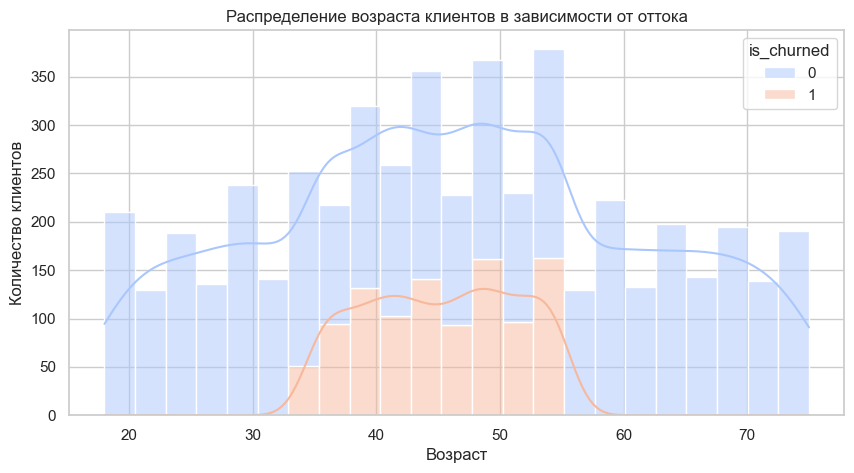

Мы видим, что пик ушедших клиентов смещен в сторону 35–55 лет. Значит, возраст — сильный признак для нашей модели.


In [27]:
#1. Как возраст влияет на отток? (Гистограмма распределения)
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='age', hue='is_churned', kde=True, multiple='stack', palette='coolwarm')
plt.title('Распределение возраста клиентов в зависимости от оттока')
plt.xlabel('Возраст')
plt.ylabel('Количество клиентов')
plt.show()
print('Мы видим, что пик ушедших клиентов смещен в сторону 35–55 лет. Значит, возраст — сильный признак для нашей модели.')

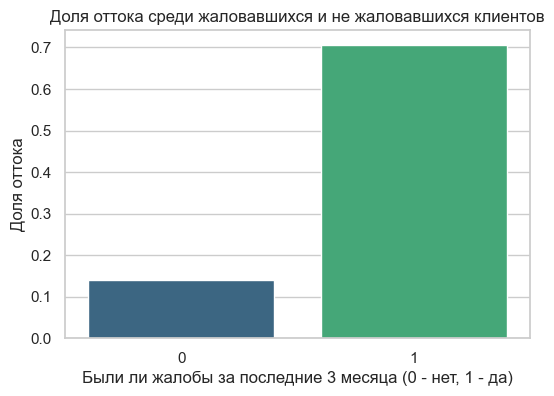

Доля оттока среди тех, кто жаловался, в разы выше. Наличие жалобы — один из главных триггеров ухода.


In [28]:
#2. Как жалобы влияют на отток? (Bar Plot)
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x='complaints_count_3m', hue='complaints_count_3m', y='is_churned', errorbar=None, palette='viridis',legend=False)
plt.title('Доля оттока среди жаловавшихся и не жаловавшихся клиентов')
plt.xlabel('Были ли жалобы за последние 3 месяца (0 - нет, 1 - да)')
plt.ylabel('Доля оттока')
plt.show()
print('Доля оттока среди тех, кто жаловался, в разы выше. Наличие жалобы — один из главных триггеров ухода.')

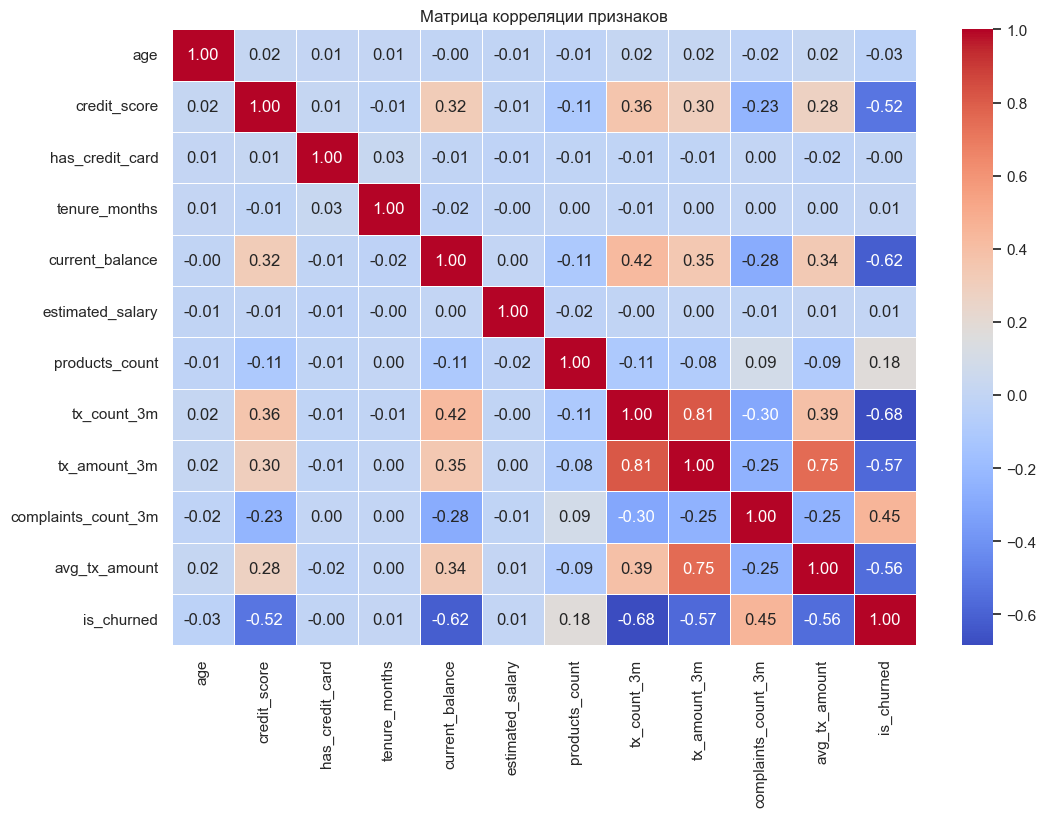

In [29]:
#3. Корреляционная матрица (Связь всех признаков)
# Для корреляции берем только числовые колонки (удаляем текстовый gender и client_id)
numeric_df = df.drop(columns=['client_id', 'gender'])
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Матрица корреляции признаков')
plt.show()

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Выделяем признаки и целевую переменную
# Убираем client_id (он не несет предсказательной силы) и сам таргет
X = df.drop(columns=['client_id', 'is_churned'])
y = df['is_churned']

# 2. Кодируем категориальный признак 'gender' (One-Hot Encoding)
# Из одной колонки 'gender' получится две: 'gender_M' и 'gender_F' (с 0 и 1)
X = pd.get_dummies(X, columns=['gender'], drop_first=True) 
# drop_first=True удаляет одну колонку, чтобы избежать дублирования информации (оставляем только gender_M: 1-мужчина, 0-женщина)

# 3. Разбиваем данные на обучающую (Train) и тестовую (Test) выборки (80% на 20%)
# stratify=y гарантирует, что и в train, и в test будет одинаковое соотношение ушедших клиентов (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")


Размер обучающей выборки: (4000, 12)
Размер тестовой выборки: (1000, 12)


Обучение Logistic Regression...

Обучение Random Forest...

РЕЗУЛЬТАТЫ: ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       793
           1       0.95      1.00      0.98       207

    accuracy                           0.99      1000
   macro avg       0.98      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000

ROC-AUC Score: 0.9999

РЕЗУЛЬТАТЫ: СЛУЧАЙНЫЙ ЛЕС
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       793
           1       1.00      1.00      1.00       207

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000

ROC-AUC Score: 1.0000

Precision (Точность): Какая доля клиентов, которых модель назвала "уходящими", действительно ушла. Если precision = 0.70, значит, в 30% случаев модель бьет ложную тревогу.

Recal

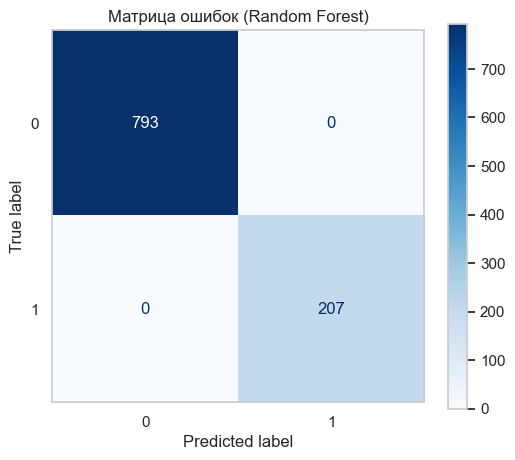

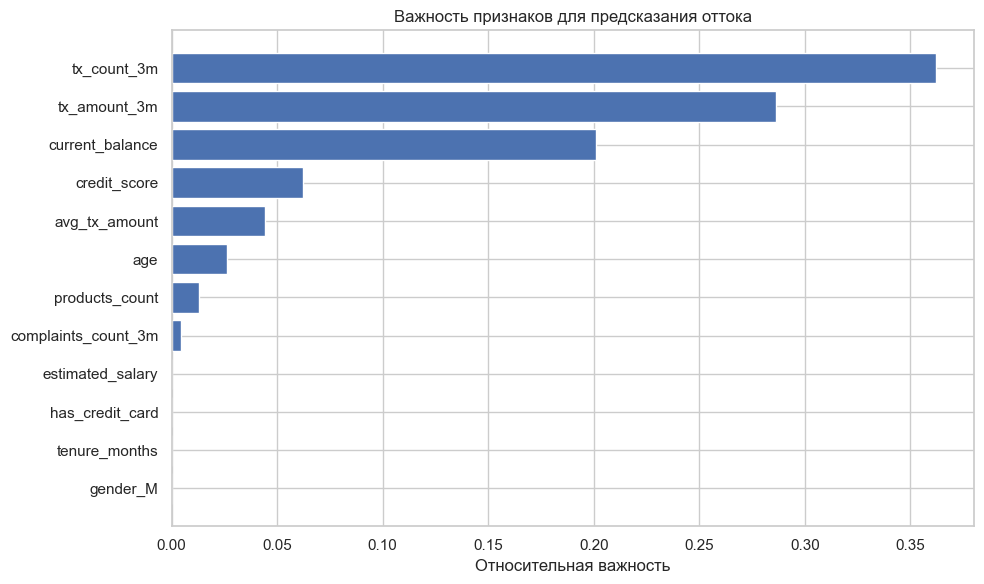

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

# Поскольку Логистическая регрессия чувствительна к масштабу признаков, 
# отмасштабируем данные с помощью StandardScaler.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- 1. ОБУЧЕНИЕ ЛОГИСТИЧЕСКОЙ РЕГРЕССИИ ---
print("Обучение Logistic Regression...")
lr_model = LogisticRegression(class_weight='balanced', random_state=42)
lr_model.fit(X_train_scaled, y_train)

# Получаем предсказания классов и вероятностей
lr_preds = lr_model.predict(X_test_scaled)
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]


# --- 2. ОБУЧЕНИЕ СЛУЧАЙНОГО ЛЕСА ---
print("\nОбучение Random Forest...")
# Ограничим глубину деревьев (max_depth=6), чтобы модель не переобучилась
rf_model = RandomForestClassifier(n_estimators=100, max_depth=6, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train) # Случайный лес не требует масштабирования признаков

# Получаем предсказания классов и вероятностей
rf_preds = rf_model.predict(X_test)
rf_probs = rf_model.predict_proba(X_test)[:, 1]


# --- 3. СРАВНЕНИЕ МЕТРИК ---
print("\n" + "="*50)
print("РЕЗУЛЬТАТЫ: ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ")
print("="*50)
print(classification_report(y_test, lr_preds))
print(f"ROC-AUC Score: {roc_auc_score(y_test, lr_probs):.4f}")

print("\n" + "="*50)
print("РЕЗУЛЬТАТЫ: СЛУЧАЙНЫЙ ЛЕС")
print("="*50)
print(classification_report(y_test, rf_preds))
print(f"ROC-AUC Score: {roc_auc_score(y_test, rf_probs):.4f}")

print('\nPrecision (Точность): Какая доля клиентов, которых модель назвала "уходящими", действительно ушла. Если precision = 0.70, значит, в 30% случаев модель бьет ложную тревогу.')
print('\nRecall (Полнота): Какую долю из всех реально ушедших клиентов модель смогла обнаружить. Это критическая метрика для бизнеса. Если recall = 0.85, значит, банк успеет удержать 85% потенциально теряемых клиентов.')
print('\nROC-AUC: Общее качество модели. Чем ближе к 1.0, тем лучше модель разделяет лояльных и склонных к оттоку клиентов. Значение выше 0.85 на наших сгенерированных данных будет отличным результатом.')

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, cmap='Blues', ax=ax)
plt.title('Матрица ошибок (Random Forest)')
plt.grid(False) # Отключаем сетку для чистоты графика
plt.show()

# Получаем важность признаков
importances = rf_model.feature_importances_
feature_names = X_train.columns

# Сортируем их по возрастанию
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.title('Важность признаков для предсказания оттока')
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Относительная важность')
plt.tight_layout()
plt.show()


In [40]:
import joblib

# Сохраняем модель Случайного леса
joblib.dump(rf_model, 'rf_model.pkl')

# Сохраняем скейлер (он пригодится, если захотите переключаться на логистическую регрессию)
joblib.dump(scaler, 'scaler.pkl')

print("Модели успешно сохранены в файлы .pkl!")


Модели успешно сохранены в файлы .pkl!
